In [55]:
import pandas as pd
import seaborn as sns
import plotly.graph_objects as go
import scipy.stats as st
import matplotlib.pyplot as plt

## Подготовка данных

In [2]:
users = pd.read_excel('dannye.xlsx', sheet_name=0)

In [3]:
payments = pd.read_excel('dannye.xlsx', sheet_name=1)

### Проверяем таблицу users

In [4]:
# посмотрим, как выглядят данные
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [5]:
# удалим дубликаты по всей таблице, если они есть в данных
users = users.drop_duplicates()

In [6]:
# посмотрим общую информацию
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


Здесь по количеству non-null значений видим, что в столбцах group и city есть пропуски. Наличие города в данных нам не так важно. А вои понимание к какой группе относится пользователь для AB теста - важно, поэтому этот user_id надо исключить.

In [7]:
users.query('group.isna()')

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


In [8]:
# также проверим, есть ли данные о группе этого пользователя в платежах. оказалось, что там юзера с таким id вообще нет, 
# поэтому можем его не учитывать
payments.query('user_id == 9001')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [9]:
# оставляем только строки, где group не пустая. Пользователь с юзером 9001 не будет учитываться в результатах AB теста
users = users[users['group'].notna()]

In [10]:
# проверим, что пользователи распределены равномерно между группами
users['group'].value_counts(dropna=False)

group
A    752
B    751
Name: count, dtype: int64

In [11]:
#посмотрим диапазон id, по которым у нас есть данные
users.user_id.describe()

count    1503.000000
mean     1764.976048
std       540.460906
min      1001.000000
25%      1376.500000
50%      1752.000000
75%      2127.500000
max      9004.000000
Name: user_id, dtype: float64

Здесь видим, что у нас 1503 строки, но при этом максимальное значение user_id - 9004. Значит, либо есть ошибка в заполнении номера id, либо какие-то данные потеряны.

In [12]:
# проверим, что все id уникальны и по ним нет повторений в таблице - это так
users['user_id'].is_unique

True

In [13]:
# посмотрим на данные после 75% квантиля, чтобы понять сохраняется ли там порядок нумерации
users.query('user_id > 2127')

,user_id,group,age,city,device_type
1127,2128,B,33,Москва,android
1128,2129,B,32,СПб,ios
1129,2130,B,35,Регион,android
1130,2131,B,32,Регион,ios
1131,2132,B,33,Регион,android
...,...,...,...,...,...
1498,2499,B,42,Москва,ios
1499,2500,B,39,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


Видим, что после user_id 2500 сразу идет 9002, это странно, как будто какие-то данные потеряны. Для некоторых из этих данных указан неверный возраст и в одном из user_id как раз пропущен city.

In [14]:
# проверим также правильность данных в остальных колонках. В возрасте есть очевидные нарушения. Минимальный -5, максимальный 150, это странные данные.
users.age.describe()

count    1503.000000
mean       32.750499
std         8.411339
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64

In [15]:
# выявим пользователей с возрастом, который не может соответствовать действительности. Это пользователи 9002 и 9003
users.query('age < 18 or age > 122')

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


Также проверим, что в остальных данных нет некорректных значений.

In [16]:
users.city.value_counts(dropna=False)

city
Москва    594
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64

In [17]:
users.device_type.value_counts(dropna=False)

device_type
android    777
ios        726
Name: count, dtype: int64

In [18]:
users.group.value_counts(dropna=False)

group
A    752
B    751
Name: count, dtype: int64

In [19]:
# посмотрим, есть ли в таблице users пользователи, которых нет в payments. Такие оказались, это уже известные нам 9002 и 9003
users[users['user_id'].isin(payments['user_id']) == False]

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [20]:
# исключаем пользователей 9002 и 9003, так как данных по ним нет в payments
users = users[~users['user_id'].isin([9002, 9003])]

### Итоги обработки таблицы users:
- По группам пользователи распределены равномерно
- По городу, типу устройства и группе в данных нет странных искажающих значений
- У двух user_id проблемы с возрастом, и данных по ним нет в таблице payments. Их исключаем из анализа.
- У одного user_id нет группы, также исключаем из анализа.
- В таблице users основная последовательность user_id представлена значениями от 1001 до 2500, после чего встречаются идентификаторы, начинающиеся с 9000. Данные идентификаторы выделяются на фоне основной последовательности.

### Визуализация распределения по группам

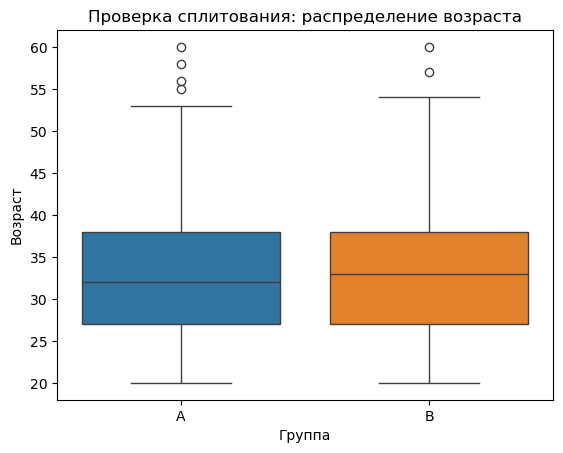

In [59]:
# посмотрим распределение по возрасту
sns.boxplot(data=users, x="group", y="age", hue='group')
plt.title("Проверка сплитования: распределение возраста")
plt.xlabel("Группа")
plt.ylabel("Возраст")

plt.show()

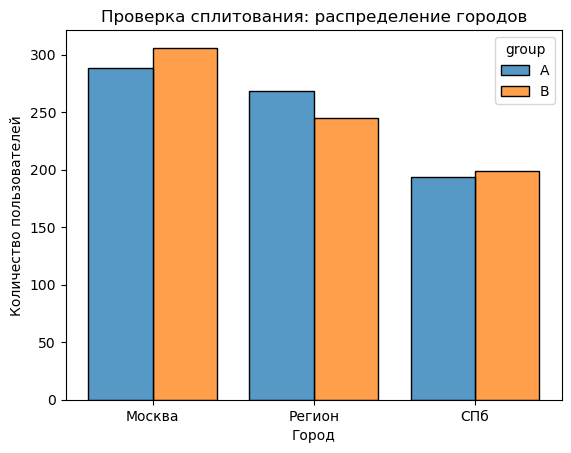

In [62]:
# посмотрим распределение по городам
sns.histplot(data=users, x="city", hue="group", multiple="dodge", shrink=0.8)
plt.title("Проверка сплитования: распределение городов")
plt.xlabel("Город")
plt.ylabel("Количество пользователей")

plt.show()

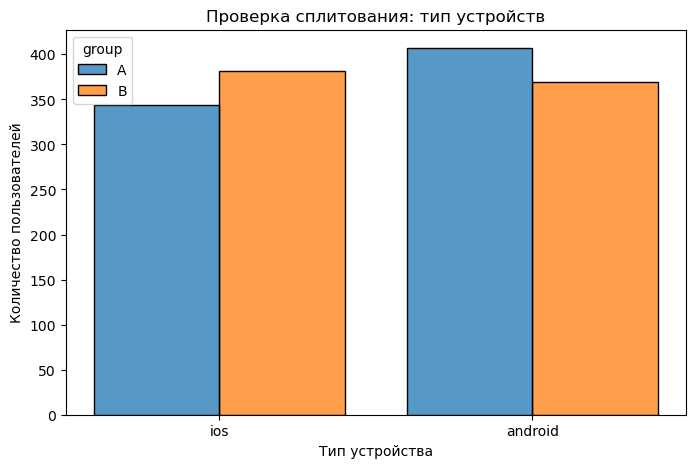

In [65]:
# посмотрим распределение по типу устройств
plt.figure(figsize=(8, 5))

sns.histplot(data=users, x="device_type", hue="group", multiple="dodge", shrink=0.8)
plt.title("Проверка сплитования: тип устройств")
plt.xlabel("Тип устройства")
plt.ylabel("Количество пользователей")

plt.show()

- Сплитование по возрасту корректно. Распределение возраста в обеих группах практически зеркально повторяет друг друга.
- Сплитование по городам выполнено корректно. Распределение пользователей по географическому признаку в группах А и Б сбалансировано, критических перекосов нет.
- Количество пользователей с iOS и Android в группах А и Б распределено сбалансированно. Незначительные визуальные разницы (например, чуть больше Android в группе А и чуть больше iOS в группе Б) находятся в пределах допустимой погрешности сплитования.

### Проверяем таблицу payments

In [21]:
# посмотрим, как выглядят данные
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [22]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB


Сразу видим, что user_id больше, чем в нашей таблице, значит, данные повторяются по каким-то пользователям.   
Для какого-то пользователя не указан его user_id

In [23]:
# удалим дубликаты, если они есть в данных. дубликатов не было. 
payments = payments.drop_duplicates()

In [24]:
# оставим только строки, где user_id не пустая, так как у нас нет данных об этом пользователе
payments = payments[payments['user_id'].notna()]

In [25]:
# проверяем, что нет дубликатов по payment_id
payments['payment_id'].is_unique

True

In [26]:
# проверяем количество уникальных пользователей в таблице
payments.user_id.nunique()

1501

<Axes: xlabel='user_id', ylabel='Count'>

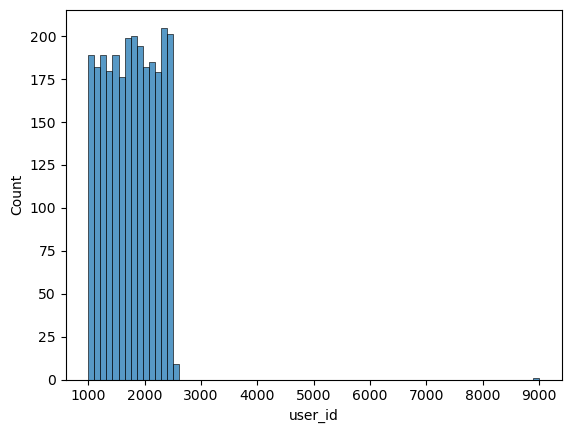

In [27]:
# посмоттрим на распределение пользователей на графике
sns.histplot(data=payments, x="user_id")

Так как уникальных пользователей меньше, чем всего строк в таблице, а на графике мы видим также диапазон в 1000-2500 нормальных user_id,  и как в таблице users несколько строк с user_id 9000, значит, на одного пользователя несколько попыток оплаты в таблице

In [28]:
# проверяем количество попыток оплаты на пользователя
payments.groupby('user_id')['payment_id'].count().value_counts().sort_index().reset_index() \
        .rename(columns={'payment_id':'payments_try', 'count': 'users'})

,payments_try,users
0,1,740
1,2,443
2,3,238
3,4,80


In [29]:
# Проверяем, есть ли пользователи с несколькими группами
group_check = payments.groupby('user_id')['group'].nunique()
group_check[group_check > 1]

user_id
1010.0    2
Name: group, dtype: int64

Пользователь 1010 указан в таблице payments с разными группами, так как в таблице users он идет под группой A, будем считать его из группы А

In [30]:
# посмотрим, есть ли в таблице payments пользователи, которых нет в users. Таких не оказалось.
payments[payments['user_id'].isin(users['user_id']) == False]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [31]:
# проверим, что по всем шагам даты - именно за апрель. Это так и есть
payments[['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']].agg(['min', 'max'])

,step1_opened,step2_entered,step3_confirmed,step4_success
min,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
max,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


Проверим, что по воронке нет ошибок в последовательности шагов по дате и все даты идут друг после друга

In [32]:
# шаг 2 не может произойти раньше шага 1
payments[payments['step2_entered'] < payments['step1_opened']]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [33]:
# шаг 3 не может произойти раньше шага 2
payments[payments['step3_confirmed'] < payments['step2_entered']]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [34]:
# шаг 4 не может произойти раньше шага 3
payments[payments['step4_success'] < payments['step3_confirmed']]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


### Подготовка таблицы с результатами AB-теста

Так A/B сплитование проводится строго по пользователю (user_id), источником правды для распределения на группы является таблица users.

In [35]:
# добавляем к таблице payments столбец группа из таблицы users
data_ab = payments.drop(columns='group').merge(users[['user_id', 'group']], on='user_id', how='inner')

In [36]:
data_ab.head()

,payment_id,user_id,step1_opened,step2_entered,step3_confirmed,step4_success,group
0,5001,1001.0,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,A
1,5002,1002.0,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,A
2,5003,1003.0,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,A
3,5004,1004.0,2024-04-09 16:02:00,NaT,NaT,NaT,A
4,5005,1004.0,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,A


В итоге для расчета результатов AB теста будем придерживаться следующей логики: если пользователь заплатил, он сконвертировался. Повторные оплаты этого же пользователя не увеличивают количество сконвертировавшихся пользователей. Если оплат нет, пользователь не сконвертировался.

In [37]:
# группируем по user_id и group и считаем для каждого степа, больше ли 0 в нем получилось число, если да - true и переводим в 1
data_ab = data_ab.groupby(['user_id', 'group'])[['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']].count() \
        .gt(0).astype(int).reset_index()

In [38]:
data_ab.head()

,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,1001.0,A,1,1,0,0
1,1002.0,A,1,1,0,0
2,1003.0,A,1,1,0,0
3,1004.0,A,1,1,1,1
4,1005.0,A,1,1,1,1


In [39]:
data_ab = data_ab.groupby('group', as_index=False).agg({'step1_opened':'sum', 'step2_entered':'sum', 'step3_confirmed':'sum', 'step4_success':'sum'})

In [40]:
data_ab

,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,A,751,672,549,494
1,B,750,707,644,603


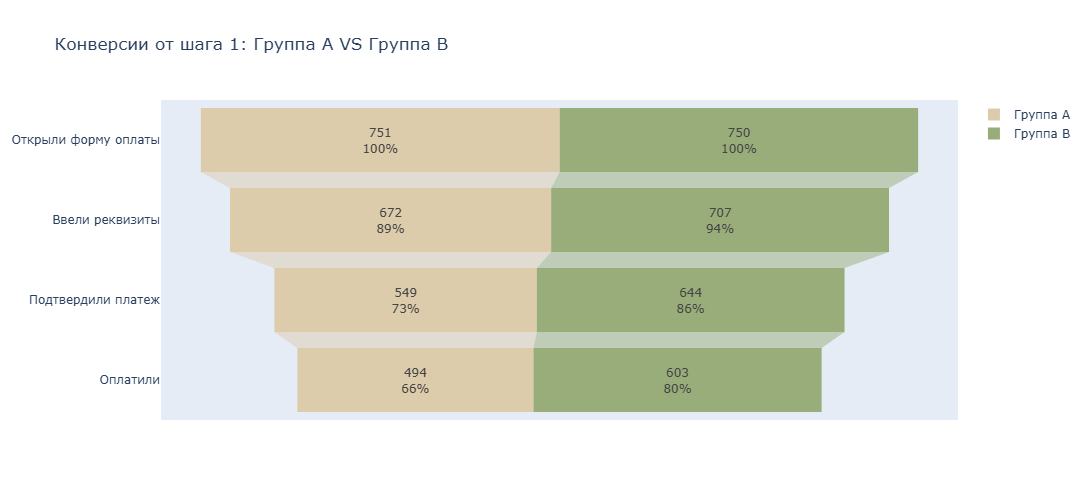

In [41]:
# визуализируем воронку
import plotly.graph_objects as go

# задаем шаги воронки
steps = ['Открыли форму оплаты', 'Ввели реквизиты', 'Подтвердили платеж', 'Оплатили']
step_columns = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']

fig = go.Figure()

# воронка для группы А 
fig.add_trace(go.Funnel(
    name='Группа A',
    y=steps,
    x=data_ab[data_ab['group'] == 'A'][step_columns].values[0],
    textinfo="value+percent initial",
    marker={"color": "#DCCCAC"}
))

# воронка для группы B
fig.add_trace(go.Funnel(
    name='Группа B',
    y=steps,
    x=data_ab[data_ab['group'] == 'B'][step_columns].values[0],
    textinfo="value+percent initial",
    marker={"color": "#99AD7A"}
))

fig.update_layout(
    title_text='Конверсии от шага 1: Группа A VS Группа B',
    width=800,
    height=500
)

fig.show()

### Считаем результаты AB теста

In [42]:
# итоговая таблица для AB теста
conversion = data_ab[['group', 'step1_opened', 'step4_success']].rename(columns={'step1_opened':'all_users', 'step4_success': 'paid_users'}) \
                                                                .set_index('group')
# считаем количество не заплативних пользователей от всех
conversion['not_paid'] = conversion['all_users'] - conversion['paid_users']
# оставляем только данные для таблицы сопряженности
conversion = conversion[['paid_users', 'not_paid']]
conversion

,paid_users,not_paid
group,,
A,494,257
B,603,147


Классический тест для сравнения конверсий между независимыми группами – тест хи квадрат, поэтому будем использовать его
- H0: Конверсия в платящих пользователей не зависит от группы (то есть конверсии в группах a и b статитически не различимы)  
- H1: Конверсия в платящих пользователей  зависит от группы (то есть конверсии в группах a и b статистически различимы)

In [43]:
st.chi2_contingency(conversion)

Chi2ContingencyResult(statistic=np.float64(40.0404018487077), pvalue=np.float64(2.4876405756565757e-10), dof=1, expected_freq=array([[548.86542305, 202.13457695],
       [548.13457695, 201.86542305]]))

Так как p-value по результатам теста хи-квадрат меньше 0,05, то можно отвергнуть нулевую гипотезу. Значит, статистически значимые различия в конверсии между группами A и B есть. 

## ВЫВОДЫ

- Гипотеза подтвердилась. В группе B, где тестировалась новая форма с автозаполнением реквизитов, конверсия в успешную оплату составила 80,4%, тогда как в контрольной группе A 65,78%
- Группа B показывает прирост конверсии на 14,62% относительно группы A. Различия между группами статистически значимы.
- Таким образом, новая форма с автозаполнением реквизитов положительно повлияла на долю успешных оплат ЖКХ. При условии корректного проведения рандомизации и отсутствия других различий между группами можно рекомендовать внедрение новой формы.